# Measles | Figure 1 — Year-adjusted regional observed/expected ratios

**Scope:** 20 Saudi MoH health regions, 2014–2023. **Goal:** create one reproducible, population-adjusted visual summary of region-level reported incidence after normalizing to each year's national reported incidence.

**Estimator:** expected cases for region *r* in year *y*: `E_ry = P_ry × (national cases_y / national population_y)`. Pool across years: `O/E_r = Σ O_ry / Σ E_ry`. **Reference line = 1.** This is not age standardization and does not identify causal determinants or transmission clusters.

**Uncertainty:** the figure shows approximate 95% Poisson count-based intervals, conditioning on fixed expected counts. National benchmark uses the same regions, so standard independent-reference inference does not hold exactly; consider conditional multinomial sensitivity analysis before publication.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2

print('Current working directory:', Path.cwd())
print('NumPy:', np.__version__, '| pandas:', pd.__version__)

Current working directory: /Users/ahmedsallam/Documents/Measles_KSA/scripts
NumPy: 1.26.4 | pandas: 2.2.2


In [3]:
# Locate project directories from notebook inside scripts/ or project root
cwd = Path.cwd()
project = cwd.parent if cwd.name == 'scripts' else cwd
possible_paths = [
    project / 'data' / 'measles_region_year.csv',
    project / 'data' / 'measles_region_year_corrected.csv',
]
source_csv = next((p for p in possible_paths if p.exists()), None)
if source_csv is None:
    raise FileNotFoundError('Place measles_region_year.csv into the project data/ folder. Checked: ' + str(possible_paths))

regional_data = pd.read_csv(source_csv, encoding='utf-8-sig')
required = {'health_region','year','reported_cases','population'}
assert required.issubset(regional_data.columns), f'Missing columns: {required - set(regional_data.columns)}'
assert not regional_data.duplicated(['health_region','year']).any(), 'Duplicate region-year records'
assert regional_data['population'].notna().all() and (regional_data['population']>0).all()
assert regional_data['reported_cases'].notna().all() and (regional_data['reported_cases']>=0).all()
assert regional_data['year'].nunique()==10 and regional_data['health_region'].nunique()==20
assert len(regional_data)==200
print('Input verified:', source_csv.name, '—', len(regional_data), 'region-year observations')

Input verified: measles_region_year.csv — 200 region-year observations


In [5]:
# National annual incidence is calculated from this SAME 20-region dataset.
# Do not treat externally published national totals as interchangeable without reconciliation.
national = regional_data.groupby('year', as_index=False).agg(
    national_cases=('reported_cases','sum'),
    national_population=('population','sum')
)
regional_oe = regional_data.merge(national, on='year', validate='many_to_one')
regional_oe['expected_cases'] = (
    regional_oe['population'] * regional_oe['national_cases'] /
    regional_oe['national_population']
)
regional_oe['oe_region_year'] = regional_oe['reported_cases'] / regional_oe['expected_cases']

# Verify annual expected cases sum to annual observed totals.
audit = regional_oe.groupby('year').agg(
    observed=('reported_cases','sum'), expected=('expected_cases','sum')
)
assert np.allclose(audit['observed'], audit['expected'], atol=1e-8)
display(audit)

# Pool observed and expected counts across all study years.
regional_summary = regional_oe.groupby('health_region',as_index=False).agg(
    observed=('reported_cases','sum'),
    expected=('expected_cases','sum'),
    total_population_exposure=('population','sum')
)
regional_summary['oe_ratio'] = regional_summary['observed']/regional_summary['expected']

# Garwood (chi-square) intervals for observed Poisson counts, divided by E.
# Here E is estimated using the national total (including each region), so intervals
# are conditional/approximate, not exact independent-comparator confidence intervals.
o = regional_summary['observed'].to_numpy(dtype=float)
e = regional_summary['expected'].to_numpy(dtype=float)
regional_summary['ci95_lower_conditional'] = np.where(
    o>0,chi2.ppf(0.025,2*o)/(2*e),0.0
)
regional_summary['ci95_upper_conditional'] = chi2.ppf(0.975,2*(o+1))/(2*e)
regional_summary = regional_summary.sort_values('oe_ratio',ascending=False).reset_index(drop=True)
display(regional_summary.round(3))

,observed,expected
year,,
2014,154,154.0
2015,219,219.0
2016,125,125.0
2017,457,457.0
2018,1156,1156.0
2019,1024,1024.0
2020,34,34.0
2021,327,327.0
2022,247,247.0


,health_region,observed,expected,total_population_exposure,oe_ratio,ci95_lower_conditional,ci95_upper_conditional
0,Qurayyat,317,33.365,1763900,9.501,8.484,10.607
1,Al-Jouf,567,67.631,3551052,8.384,7.708,9.103
2,Najran,603,108.627,5906522,5.551,5.117,6.012
3,Makkah,545,456.722,23919901,1.193,1.095,1.298
4,Jazan,322,277.746,15528022,1.159,1.036,1.293
5,Riyadh,1600,1550.511,83417447,1.032,0.982,1.084
6,Northern,55,68.465,3722828,0.803,0.605,1.046
7,Qaseem,204,256.654,14181605,0.795,0.690,0.912
8,Aseer,253,328.866,18168190,0.769,0.677,0.870
9,Medinah,300,395.170,21473746,0.759,0.676,0.850


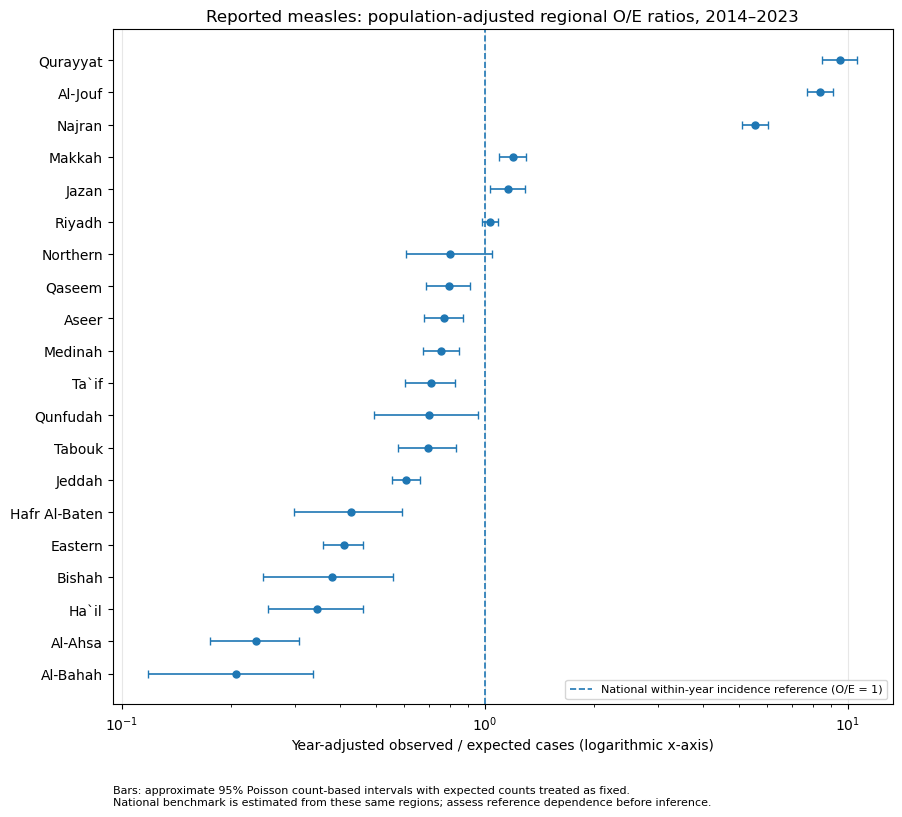

Figure PNG: /Users/ahmedsallam/Documents/Measles_KSA/figures/fig01_regional_year_adjusted_oe.png
Figure SVG: /Users/ahmedsallam/Documents/Measles_KSA/figures/fig01_regional_year_adjusted_oe.svg
Summary table: /Users/ahmedsallam/Documents/Measles_KSA/outputs/regional_year_adjusted_oe_summary.csv


In [6]:
# Visualization: region-level 10-year pooled year-adjusted O/E ratio.
# This is a methods figure, not a clinical interpretation.
fig, ax = plt.subplots(figsize=(10,9))
y = np.arange(len(regional_summary))
x = regional_summary['oe_ratio'].to_numpy()
lo = regional_summary['ci95_lower_conditional'].to_numpy()
hi = regional_summary['ci95_upper_conditional'].to_numpy()

ax.errorbar(x,y,xerr=np.vstack([x-lo,hi-x]),fmt='o',capsize=3,elinewidth=1.2,markersize=5)
ax.axvline(1.0,linestyle='--',linewidth=1.2,label='National within-year incidence reference (O/E = 1)')
ax.set_yticks(y, regional_summary['health_region'].to_list())
ax.invert_yaxis()
ax.set_xscale('log')
ax.set_xlabel('Year-adjusted observed / expected cases (logarithmic x-axis)')
ax.set_title('Reported measles: population-adjusted regional O/E ratios, 2014–2023')
ax.grid(axis='x',alpha=0.3)
ax.legend(loc='lower right',fontsize=8)
ax.text(0,-0.12,
        'Bars: approximate 95% Poisson count-based intervals with expected counts treated as fixed.\n'
        'National benchmark is estimated from these same regions; assess reference dependence before inference.',
        transform=ax.transAxes,fontsize=8,va='top')
fig.subplots_adjust(left=0.2,bottom=0.19,right=0.98,top=0.94)

figure_dir=project/'figures'; output_dir=project/'outputs'
figure_dir.mkdir(exist_ok=True);output_dir.mkdir(exist_ok=True)
plot_png=figure_dir/'fig01_regional_year_adjusted_oe.png'
plot_svg=figure_dir/'fig01_regional_year_adjusted_oe.svg'
output_csv=output_dir/'regional_year_adjusted_oe_summary.csv'
fig.savefig(plot_png,dpi=300,bbox_inches='tight')
fig.savefig(plot_svg,bbox_inches='tight')
regional_summary.to_csv(output_csv,index=False)
plt.show()
print('Figure PNG:',plot_png)
print('Figure SVG:',plot_svg)
print('Summary table:',output_csv)

## Publication and validation notes

- Estimates compare each region's cases to expected counts given *the observed national rate in each year* and that region's population. **This is not age-standardized incidence**, and a region can influence its own national benchmark.
- The displayed intervals condition on expected cases and assume a Poisson sampling model; they do not include uncertainty in the internally derived national reference or overdispersion from outbreaks. **Do not use 95% interval crossing 1 as a definitive significance criterion.** A year-conditional multinomial reference or leave-one-out sensitivity is planned next.
- Rates from published Saudi studies may reflect different years, reporting definitions and different geographic units (13 administrative regions versus our 20 health regions). Do not mix.
- Clinical interpretation of between-region variation belongs to the epidemiology team.

**Methods references:** [WHO surveillance guidance](https://www.who.int/publications/i/item/surveillance-standards-for-vaccine-preventable-diseases-2nd-edition), [WHO incidence metadata](https://immunizationdata.who.int/global/wiise-detail-page/measles-reported-cases-and-incidence?CODE=Global%26YEAR), [Spiegelhalter, uncertainty and funnel plots](https://doi.org/10.1002/sim.1970).

In [ ]:

# Calculate national incidence as cases per person
national_rates = annual[["year", "reported_cases", "population"]].copy()

national_rates["national_rate"] = (
    national_rates["reported_cases"]
    / national_rates["population"]
)

# Attach the corresponding annual national rate to each region
oe_data = regional.merge(
    national_rates[["year", "national_rate"]],
    on="year",
    how="left",
    validate="many_to_one"
)

# Calculate expected cases under the national reference rate
oe_data["expected_cases"] = (
    oe_data["population"] * oe_data["national_rate"]
)

display(oe_data.head())


NameError: name 'oe_data' is not defined